In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
import ast

# Visual configuration
COMP_PALETTE = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#76b7b2"]
COMP_LABELS = ["C1", "C2", "C3", "C4", "C5"]
PRIMARY_CLR = "#2c7bb6"
SCORE_STEPS = [0, 40, 80, 120, 160, 200]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SAVE = True # Set True to export PDFs
FIG_DIR = "figures_official" # Choose the directory of the exportation
if SAVE:
    os.makedirs(FIG_DIR, exist_ok=True)

def _save(name):
    if SAVE:
        plt.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

LABEL_MAX = 55 # Maximum number of characters before truncating prompt labels in figures
def _shorten(text, n=LABEL_MAX):
    return text if len(text) <= n else text[:n].rstrip() + "\u2026"

HF_CACHE = os.path.join(os.path.expanduser("~"), "hf_cache")
os.makedirs(HF_CACHE, exist_ok=True)
print(f"HuggingFace cache: {HF_CACHE}")

HuggingFace cache: C:\Users\User\hf_cache


#### Load and Prepare the Data

In [ ]:
print("Loading official ENEM dataset...")
dataset = load_dataset(
    "laisnuto/self-collected-ENEM-dataset-with-prompts-and-text-support",
    cache_dir=HF_CACHE,
)
df = dataset["train"].to_pandas()

# Parse 'notas' from string to individual competency columns
def _parse_notas(val):
    return ast.literal_eval(val) if isinstance(val, str) else list(val)

grades_df = pd.DataFrame(
    df["notas"].apply(_parse_notas).tolist(),
    index=df.index,
    columns=COMP_LABELS,
)
df = pd.concat([df, grades_df], axis=1)

# Coerce types
for c in COMP_LABELS:
    df[c] = df[c].astype(int)
df["nota_final"] = df["nota_final"].astype(float)
df["ano"] = df["ano"].astype(int)

# Computed total for cross-validation
df["Total_Score"] = df[COMP_LABELS].sum(axis=1)

# Shorten prompt labels for readability in figures
df["prompt_short"] = df["prompt"].apply(_shorten)

print(f"Loaded {len(df):,} essays")
print(f"Years in corpus: {sorted(df['ano'].unique())}")

Loading official ENEM dataset...
Loaded 157 essays
Years in corpus: [np.int64(2016), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [3]:
print("Shape:", df.shape)
print("\nMissing values in key columns:")
print(df[["ano", "prompt", "nota_final"] + COMP_LABELS].isnull().sum())
print("\nUnique score values per competency:")
for c in COMP_LABELS:
    print(f"  {c}: {sorted(df[c].unique())}")

Shape: (157, 13)

Missing values in key columns:
ano           0
prompt        0
nota_final    0
C1            0
C2            0
C3            0
C4            0
C5            0
dtype: int64

Unique score values per competency:
  C1: [np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200)]
  C2: [np.int64(40), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200)]
  C3: [np.int64(40), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200)]
  C4: [np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200)]
  C5: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200)]


In [4]:
df[["ano", "prompt_short", "C1", "C2", "C3", "C4", "C5", "nota_final"]].head(5)

,ano,prompt_short,C1,C2,C3,C4,C5,nota_final
0,2018,A partir da leitura dos textos motivadores e c...,120,120,160,160,160,720.0
1,2021,A partir da leitura dos textos motivadores e c...,160,200,160,200,180,900.0
2,2019,A partir da leitura dos textos motivadores e c...,160,160,160,160,200,840.0
3,2018,A partir da leitura dos textos motivadores e c...,160,120,120,140,140,680.0
4,2019,A partir da leitura dos textos motivadores e c...,180,200,160,200,160,900.0


#### Descriptive statistics

In [5]:
stats = (
    df[COMP_LABELS + ["nota_final"]]
    .describe()
    .T
    .rename(columns={
        "count": "N", "mean": "Mean", "std": "Std Dev",
        "min": "Min", "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Max",
    })
)
stats["N"] = stats["N"].astype(int)
stats = stats.round(2)
stats.index.name = "Metric"
stats

,N,Mean,Std Dev,Min,Q1,Median,Q3,Max
Metric,,,,,,,,
C1,157,156.18,18.42,100.0,140.0,160.0,160.0,200.0
C2,157,177.20,34.08,40.0,160.0,200.0,200.0,200.0
C3,157,162.68,30.64,40.0,140.0,160.0,180.0,200.0
C4,157,174.39,27.72,100.0,160.0,180.0,200.0,200.0
C5,157,169.04,37.58,40.0,160.0,180.0,200.0,200.0
nota_final,157,839.49,122.37,380.0,780.0,900.0,920.0,980.0


#### Number of essays per year

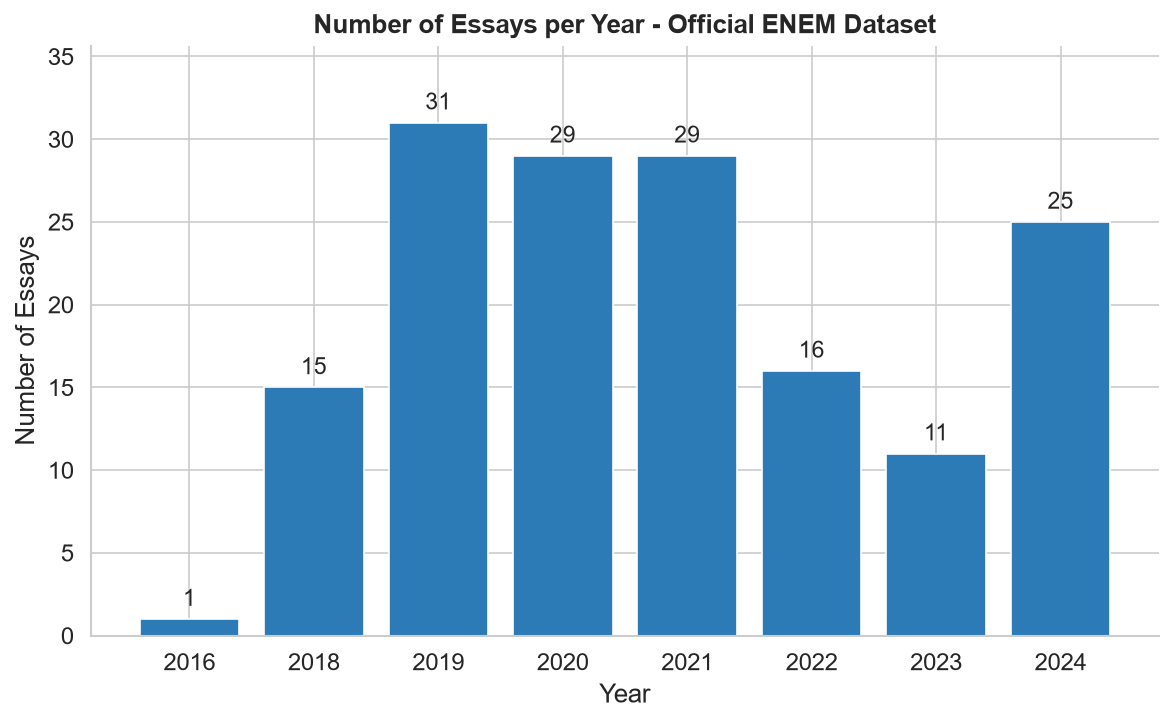

In [6]:
year_counts = df["ano"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    year_counts.index.astype(str), year_counts.values,
    color=PRIMARY_CLR, edgecolor="white", linewidth=0.8,
)
ax.bar_label(bars, padding=4, fontsize=11)
ax.set_title("Number of Essays per Year - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Essays")
ax.set_ylim(0, year_counts.max() * 1.15)
plt.tight_layout()
_save("01_essays_per_year")
plt.show()

#### Number of essays per prompt

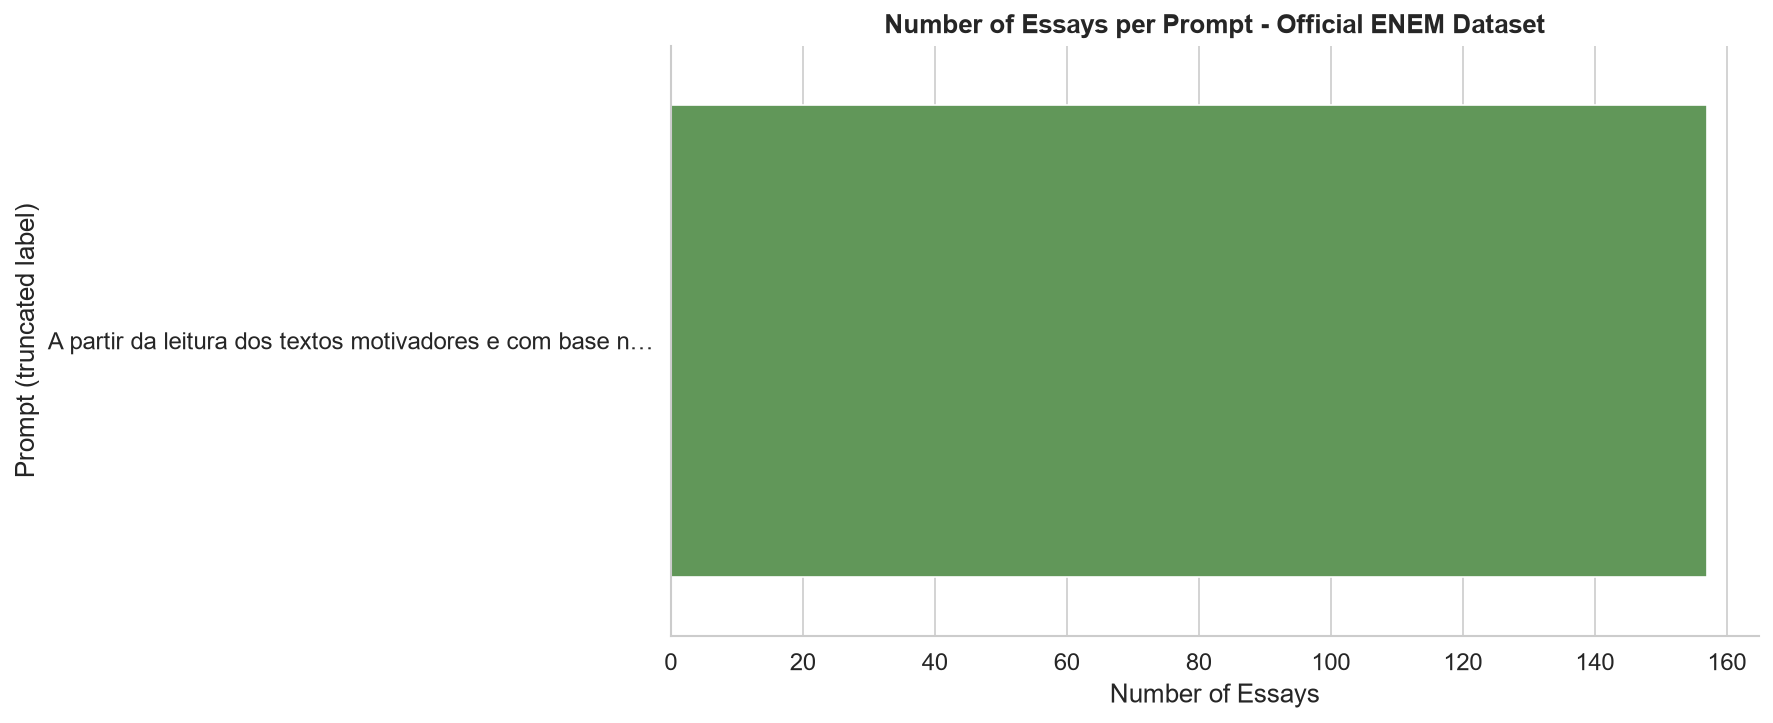

In [7]:
order_short = (
    df.groupby("prompt_short")
    .size()
    .sort_values(ascending=False)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, max(5, len(order_short) * 0.45)))
sns.countplot(data=df, y="prompt_short", order=order_short, color=COMP_PALETTE[2], ax=ax)
ax.set_title("Number of Essays per Prompt - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Number of Essays")
ax.set_ylabel("Prompt (truncated label)")
plt.tight_layout()
_save("02_essays_per_prompt")
plt.show()

#### Number of essays per prompt per year

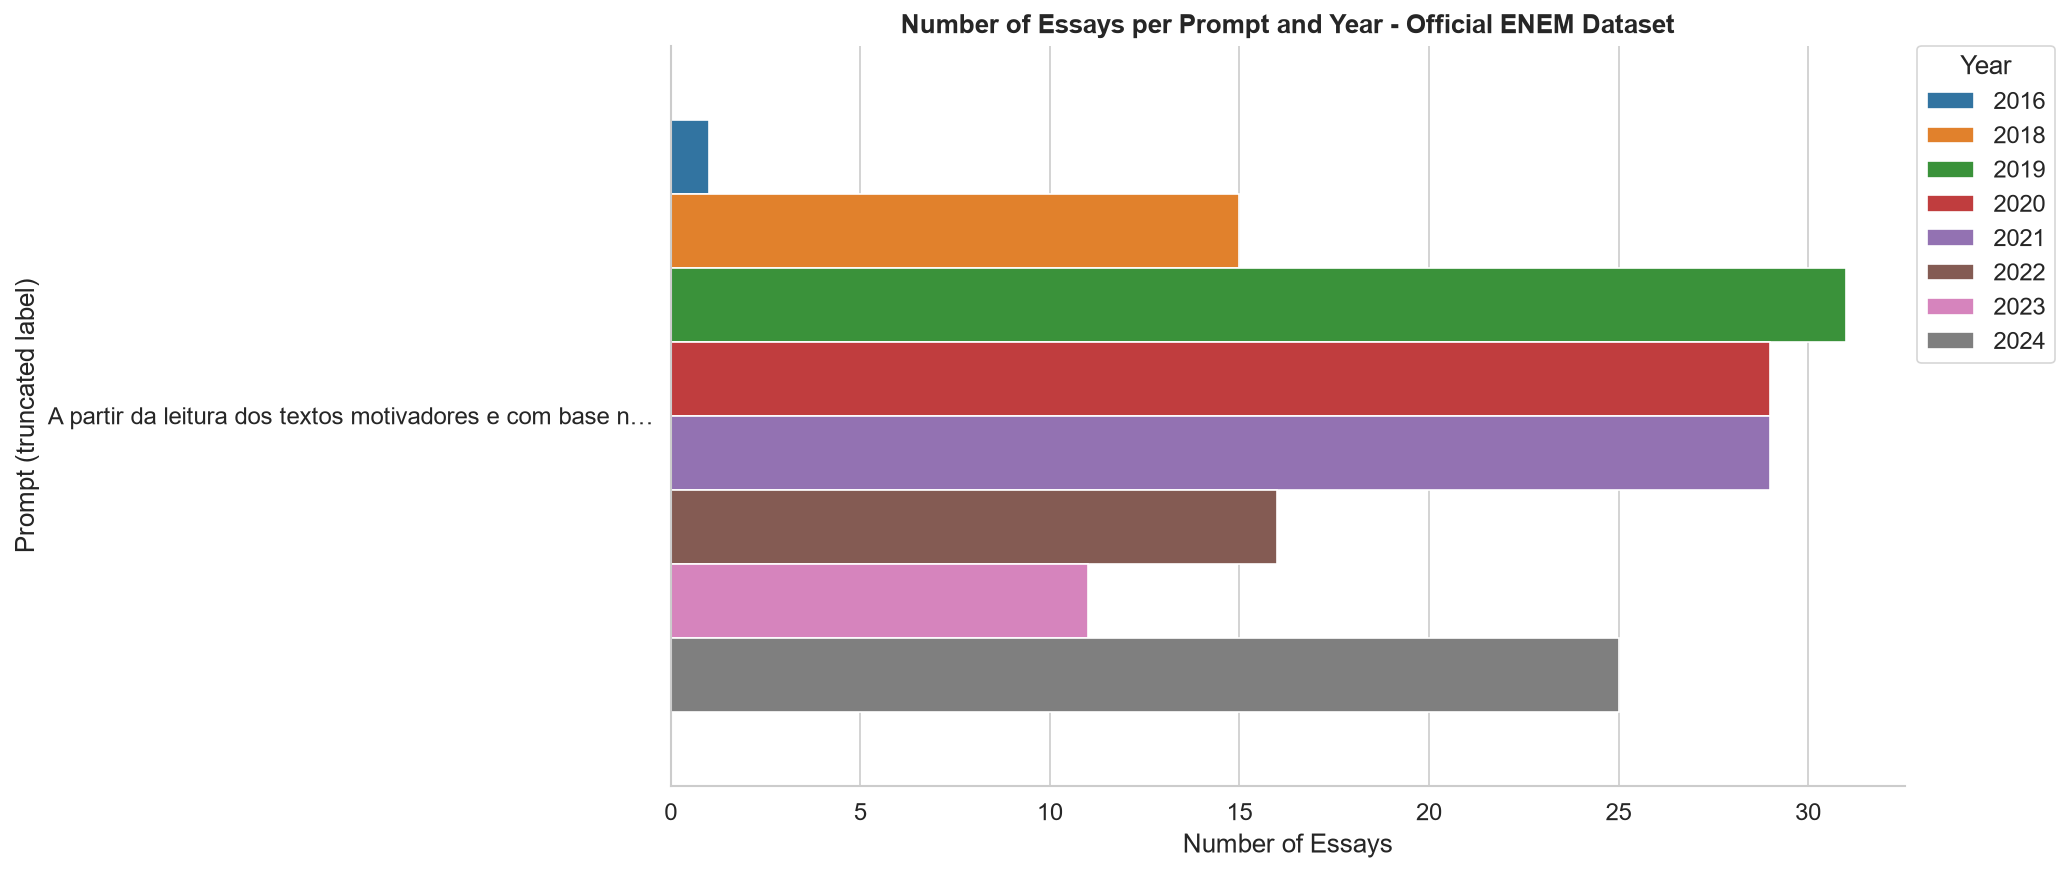

In [8]:
fig, ax = plt.subplots(figsize=(14, max(6, len(order_short) * 0.5)))
sns.countplot(
    data=df, y="prompt_short", hue="ano",
    order=order_short, palette="tab10", ax=ax,
)
ax.set_title("Number of Essays per Prompt and Year - Official ENEM Dataset",
             fontweight="bold")
ax.set_xlabel("Number of Essays")
ax.set_ylabel("Prompt (truncated label)")
ax.legend(title="Year", bbox_to_anchor=(1.01, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
_save("03_essays_per_prompt_year")
plt.show()

#### Distribution of scores by competency

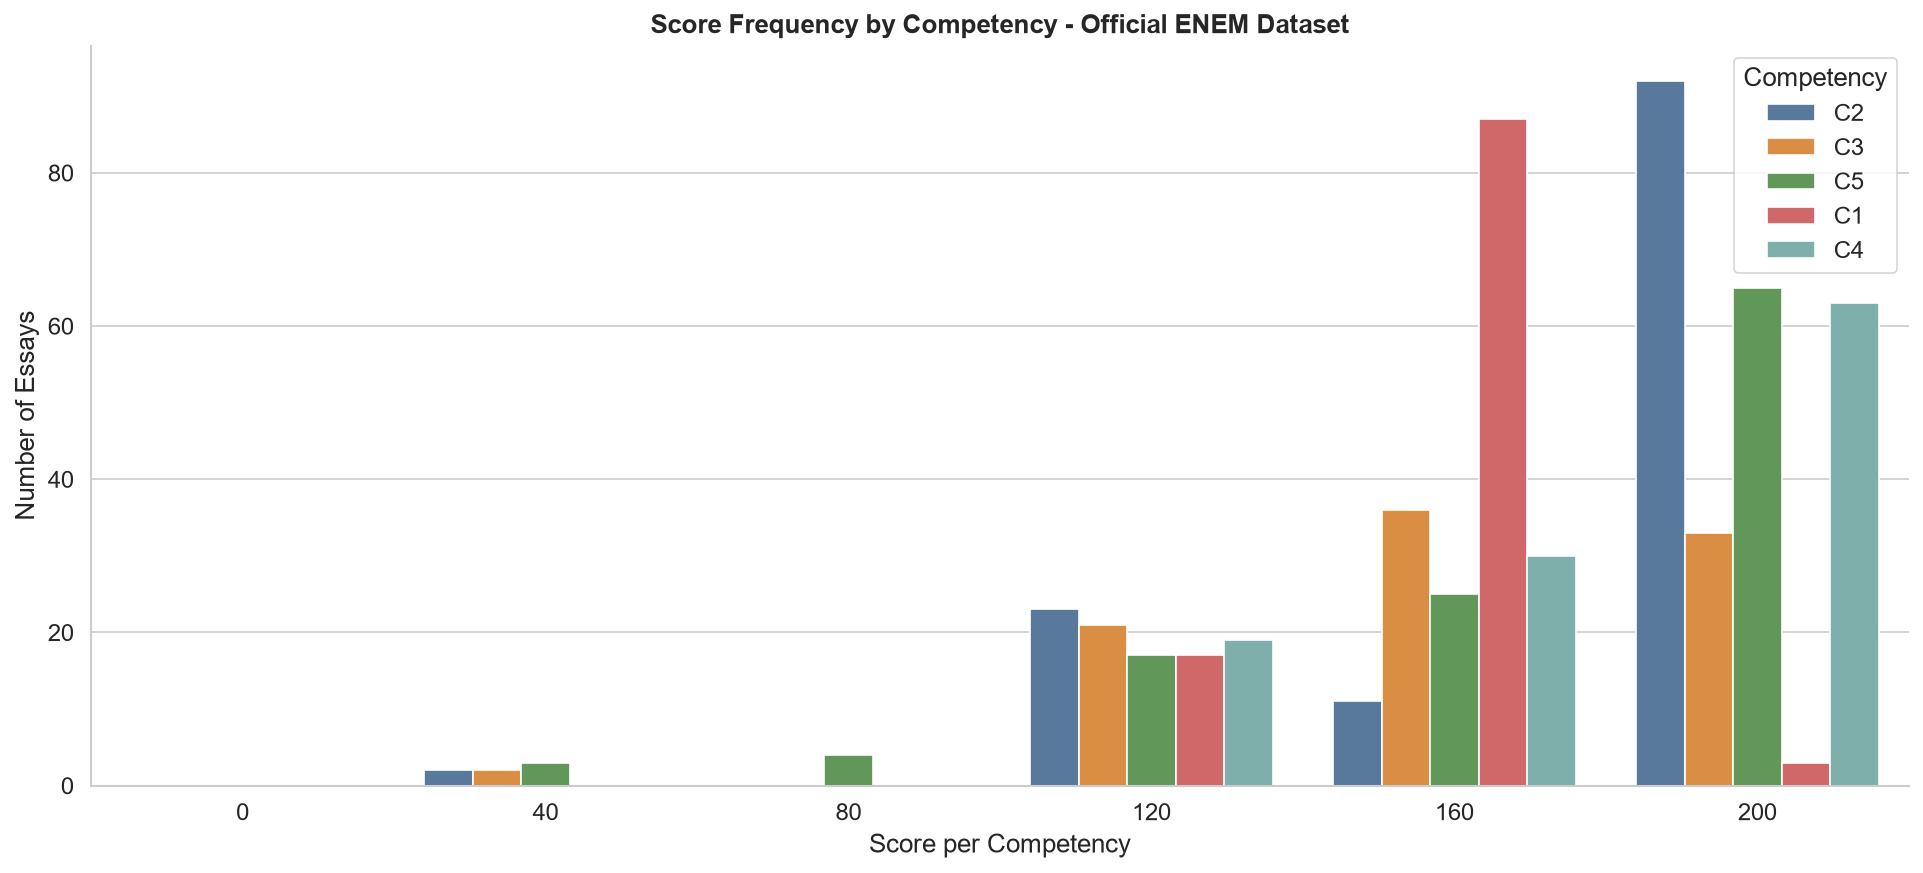

In [9]:
# Transform data to melted for Seaborn
df_melted = df.melt(
    value_vars=COMP_LABELS,
    var_name="Competency",
    value_name="Score",
)

# Grouped Bar Chart
fig, ax = plt.subplots(figsize=(13, 6))
sns.countplot(
    data=df_melted,
    x="Score",
    hue="Competency",
    order=SCORE_STEPS,
    palette=COMP_PALETTE,
    ax=ax,
)
ax.set_title("Score Frequency by Competency - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Score per Competency")
ax.set_ylabel("Number of Essays")
ax.legend(title="Competency", frameon=True)
plt.tight_layout()
_save("04a_score_freq_by_competency")
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_21532\3471182049.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


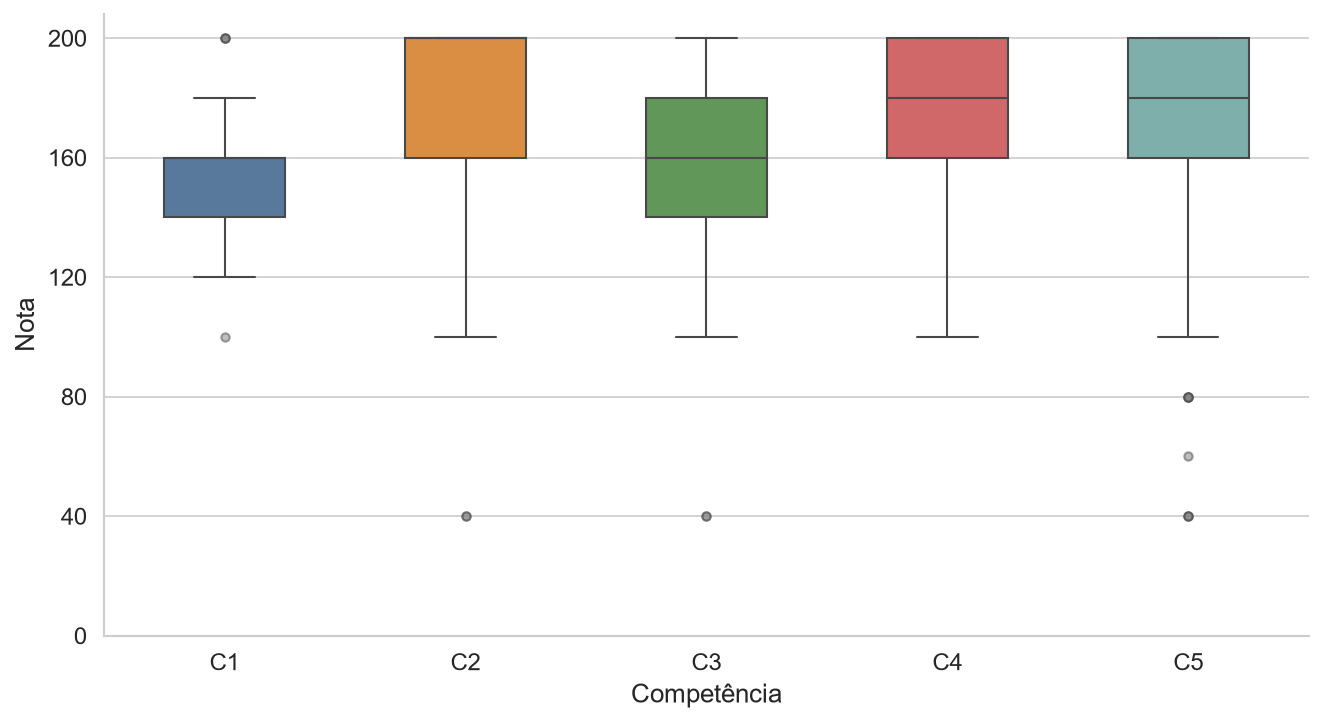

In [16]:
# Box Plot
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=df_melted,
    x="Competency",
    y="Score",
    order=COMP_LABELS,
    palette=COMP_PALETTE,
    width=0.5,
    flierprops=dict(marker="o", markerfacecolor="grey", markersize=4, alpha=0.5),
    ax=ax,
)
# ax.set_title("Score Spread by Competency - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Competência")
ax.set_ylabel("Nota")
ax.set_yticks(SCORE_STEPS)
plt.tight_layout()
_save("04b_score_boxplot")
plt.show()

#### Competence score correlation

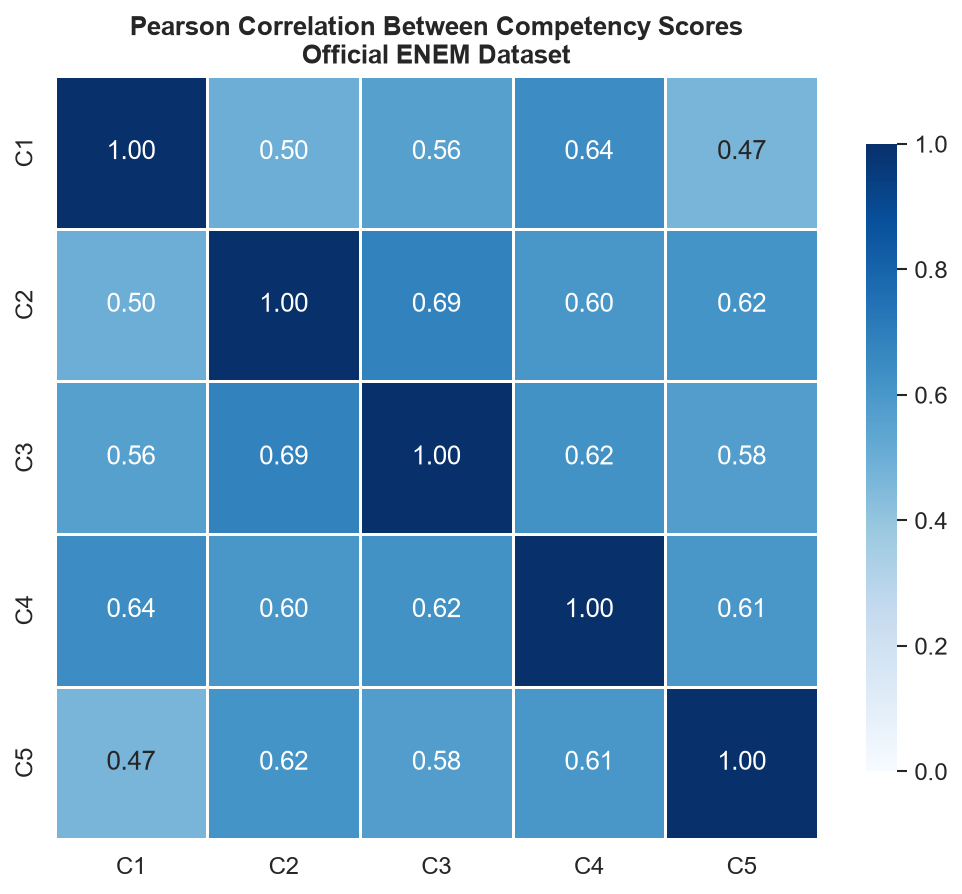

In [ ]:
corr = df[COMP_LABELS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True, fmt=".2f",
    cmap="Blues", vmin=0, vmax=1,
    linewidths=0.5, square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Pearson Correlation Between Competency Scores\nOfficial ENEM Dataset", fontweight="bold")
plt.tight_layout()
_save("05_competency_correlation")
plt.show()

#### Number of essays per maximum possible score

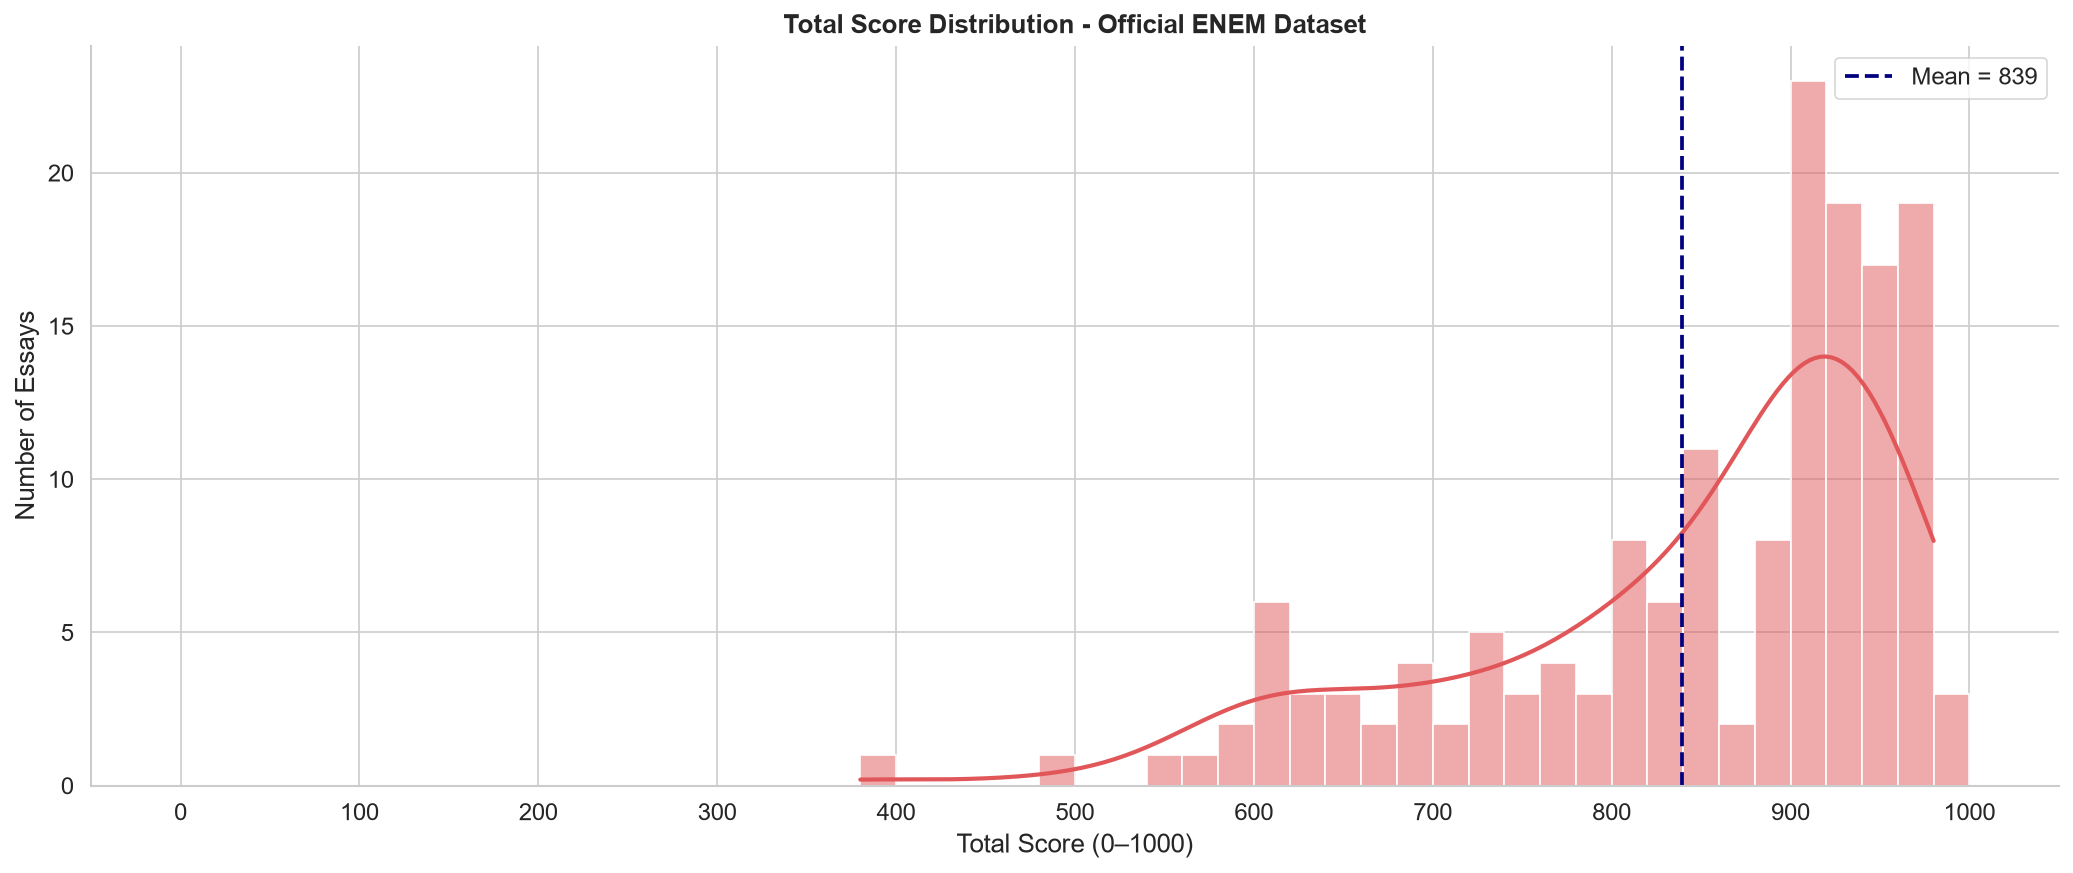

Mean   : 839.5
Median : 900.0
Std Dev: 122.4
Min / Max : 380 / 980


In [ ]:
bins = np.arange(0, 1020, 20)
mean_val = df["nota_final"].mean()

fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(
    data=df, x="nota_final",
    bins=bins,
    color=COMP_PALETTE[3],
    kde=True,
    line_kws={"linewidth": 2},
    ax=ax,
)
ax.axvline(mean_val, color="navy", linestyle="--", linewidth=1.8, label=f"Mean = {mean_val:.0f}")
ax.set_title("Total Score Distribution - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Total Score (0–1000)")
ax.set_ylabel("Number of Essays")
ax.set_xticks(range(0, 1001, 100))
ax.legend()
plt.tight_layout()
_save("06_total_score_distribution")
plt.show()

print(f"Mean   : {df['nota_final'].mean():.1f}")
print(f"Median : {df['nota_final'].median():.1f}")
print(f"Std Dev: {df['nota_final'].std():.1f}")
print(f"Min / Max : {df['nota_final'].min():.0f} / {df['nota_final'].max():.0f}")

#### Token truncation analysis (BERTimbau-base)

In [ ]:
print("Loading BERTimbau tokenizer...")
tokenizer = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")

MAX_LEN = 512

df["token_count"] = df["texto"].apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
df["is_truncated"] = df["token_count"] > MAX_LEN
df["excess_tokens"] = (df["token_count"] - MAX_LEN).clip(lower=0)

n_trunc = int(df["is_truncated"].sum())
pct = n_trunc/len(df) * 100

print(f"Total essays     : {len(df):,}")
print(f"Truncated essays : {n_trunc:,}  ({pct:.2f}%)")
print(f"\nToken count statistics (all essays):")
print(df["token_count"].describe().round(1).to_string())

Loading BERTimbau tokenizer...
Total essays     : 157
Truncated essays : 44  (28.03%)

Token count statistics (all essays):
count    157.0
mean     438.3
std      121.7
min      181.0
25%      362.0
50%      417.0
75%      523.0
max      814.0


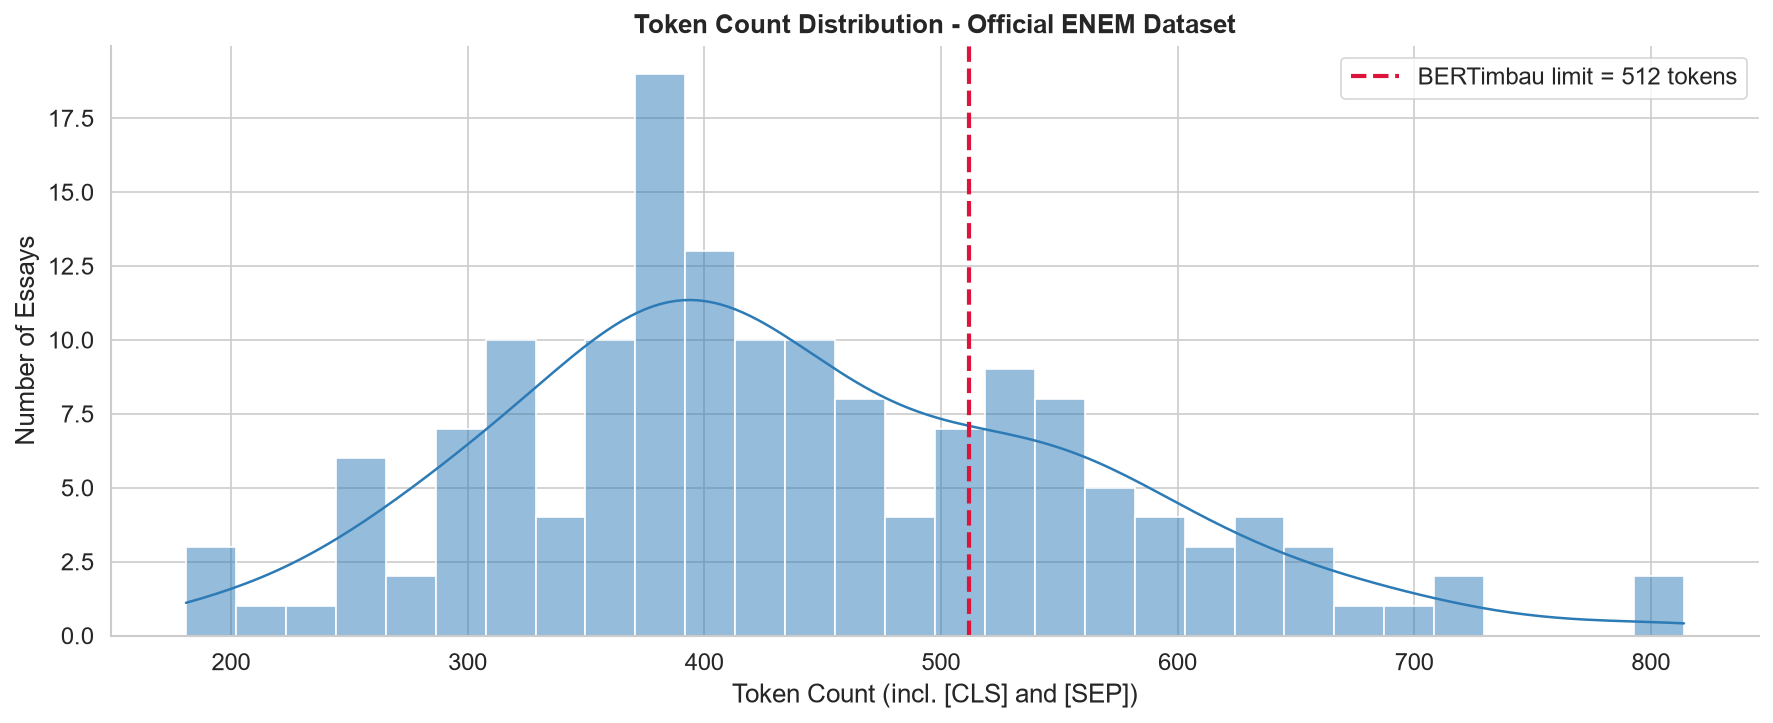

In [14]:
# Full token count distribution
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=df, x="token_count", bins=30, color=PRIMARY_CLR, kde=True, ax=ax)
ax.axvline(MAX_LEN, color="crimson", linestyle="--", linewidth=2,
           label=f"BERTimbau limit = {MAX_LEN} tokens")
ax.set_title("Token Count Distribution - Official ENEM Dataset", fontweight="bold")
ax.set_xlabel("Token Count (incl. [CLS] and [SEP])")
ax.set_ylabel("Number of Essays")
ax.legend()
plt.tight_layout()
_save("07a_token_count_dist")
plt.show()

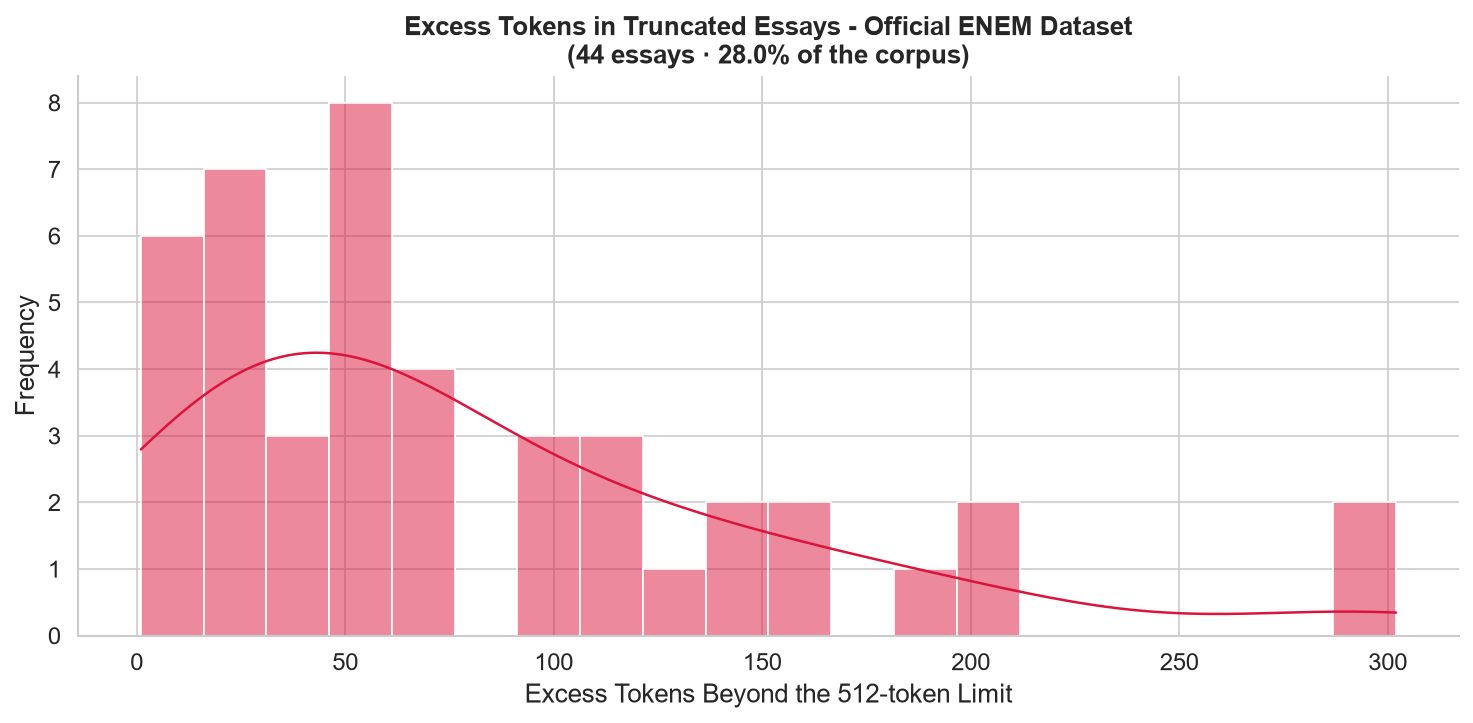

Excess token statistics (truncated essays only):
count     44.0
mean      81.9
std       72.3
min        1.0
25%       27.0
50%       57.0
75%      115.8
max      302.0


In [15]:
# Excess tokens among truncated essays
if n_trunc > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(
        data=df[df["is_truncated"]],
        x="excess_tokens",
        bins=20,
        color="crimson",
        kde=(n_trunc > 5),
        ax=ax,
    )
    ax.set_title(
        f"Excess Tokens in Truncated Essays - Official ENEM Dataset\n"
        f"({n_trunc:,} essays · {pct:.1f}% of the corpus)",
        fontweight="bold",
    )
    ax.set_xlabel("Excess Tokens Beyond the 512-token Limit")
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    _save("07b_excess_tokens")
    plt.show()

    print("Excess token statistics (truncated essays only):")
    print(df.loc[df["is_truncated"], "excess_tokens"].describe().round(1).to_string())
else:
    print("No truncated essays - all essays fit within 512 tokens.")